In [19]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Python version:", sys.version)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

print("Environment is ready!")

Python version: 3.13.1 (tags/v3.13.1:0671451, Dec  3 2024, 19:06:28) [MSC v.1942 64 bit (AMD64)]
Pandas version: 2.3.0
NumPy version: 2.3.1
Environment is ready!


In [20]:
import pandas as pd
from pathlib import Path

# FRED historical exchange-rate data
url = (
    "https://fred.stlouisfed.org/graph/fredgraph.csv"
    "?id=EXINUS&cosd=1973-01-01&coed=2024-08-31"
)

# Download dataset
df = pd.read_csv(url)

# Inspect original column names
print("Original columns:", df.columns.tolist())

# Standardize column names
df.columns = ["Date", "INR_per_USD"]

# Convert data types
df["Date"] = pd.to_datetime(df["Date"])
df["INR_per_USD"] = pd.to_numeric(
    df["INR_per_USD"], errors="coerce"
)

# Clean missing values
df = df.dropna().sort_values("Date").reset_index(drop=True)

# Save raw dataset
output_path = Path("../data/raw/inr_usd_fred_1973_2024.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(output_path, index=False)

# Display results
print("\nFirst 5 records:")
display(df.head())

print("\nLast 5 records:")
display(df.tail())

print("\nDataset shape:", df.shape)
print("Date range:", df["Date"].min(), "to", df["Date"].max())
print("Missing values:\n", df.isnull().sum())

Original columns: ['observation_date', 'EXINUS']

First 5 records:


,Date,INR_per_USD
0,1973-01-01,8.0041
1,1973-02-01,7.7538
2,1973-03-01,7.5465
3,1973-04-01,7.5462
4,1973-05-01,7.4927



Last 5 records:


,Date,INR_per_USD
615,2024-04-01,83.3968
616,2024-05-01,83.3873
617,2024-06-01,83.4600
618,2024-07-01,83.5895
619,2024-08-01,83.8855



Dataset shape: (620, 2)
Date range: 1973-01-01 00:00:00 to 2024-08-01 00:00:00
Missing values:
 Date           0
INR_per_USD    0
dtype: int64


In [21]:
# Basic statistical summary
print("Statistical Summary:")
display(df["INR_per_USD"].describe())

# Check chronological data
print("First 10 observations:")
display(df.head(10))

# Check yearly coverage
yearly_count = df.groupby(df["Date"].dt.year).size()

print("Observations per year:")
display(yearly_count.head())

Statistical Summary:


count    620.000000
mean      37.033540
std       23.279379
min        7.271900
25%       12.430500
50%       40.056000
75%       49.427675
max       83.885500
Name: INR_per_USD, dtype: float64

First 10 observations:


,Date,INR_per_USD
0,1973-01-01,8.0041
1,1973-02-01,7.7538
2,1973-03-01,7.5465
3,1973-04-01,7.5462
4,1973-05-01,7.4927
5,1973-06-01,7.2719
6,1973-07-01,7.3510
7,1973-08-01,7.5643
8,1973-09-01,7.7000
9,1973-10-01,7.7271


Observations per year:


Date
1973    12
1974    12
1975    12
1976    12
1977    12
dtype: int64

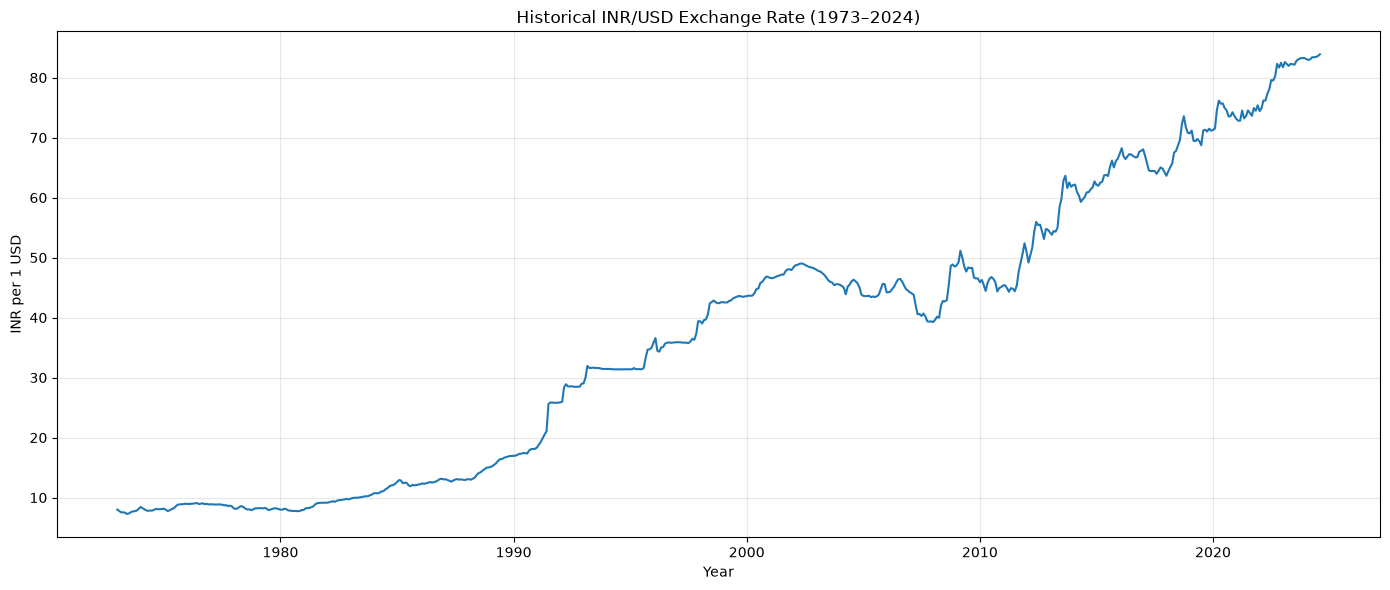

In [22]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["Date"],
    df["INR_per_USD"],
    linewidth=1.5
)

plt.title("Historical INR/USD Exchange Rate (1973–2024)")
plt.xlabel("Year")
plt.ylabel("INR per 1 USD")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

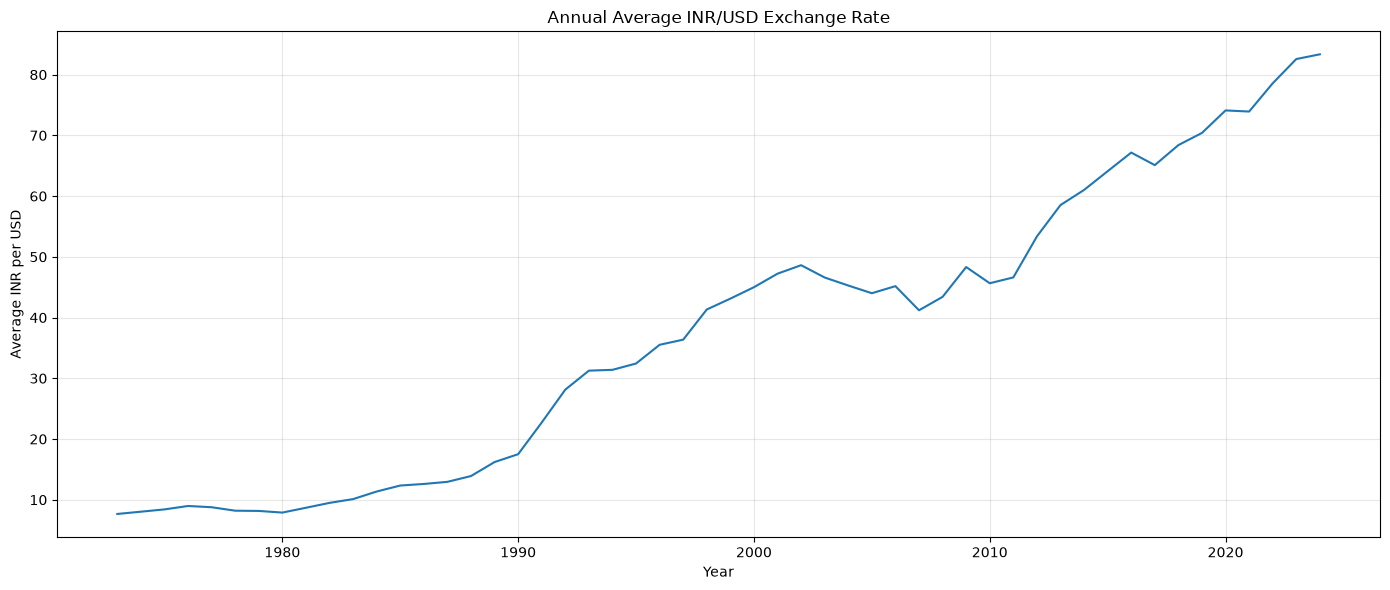

In [23]:
yearly_avg = (
    df.set_index("Date")["INR_per_USD"]
      .resample("YE")
      .mean()
)

plt.figure(figsize=(14, 6))
plt.plot(yearly_avg.index.year, yearly_avg.values)
plt.title("Annual Average INR/USD Exchange Rate")
plt.xlabel("Year")
plt.ylabel("Average INR per USD")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

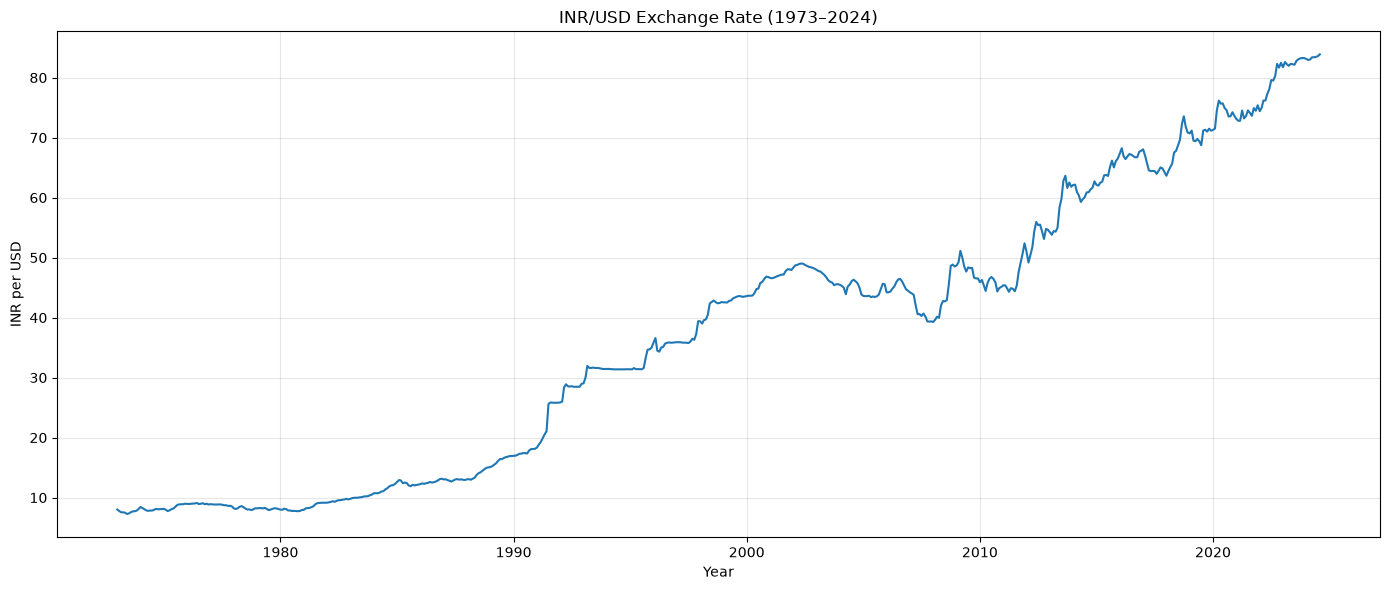

In [24]:
plt.figure(figsize=(14, 6))

plt.plot(df["Date"], df["INR_per_USD"], linewidth=1.5)

plt.title("INR/USD Exchange Rate (1973–2024)")
plt.xlabel("Year")
plt.ylabel("INR per USD")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

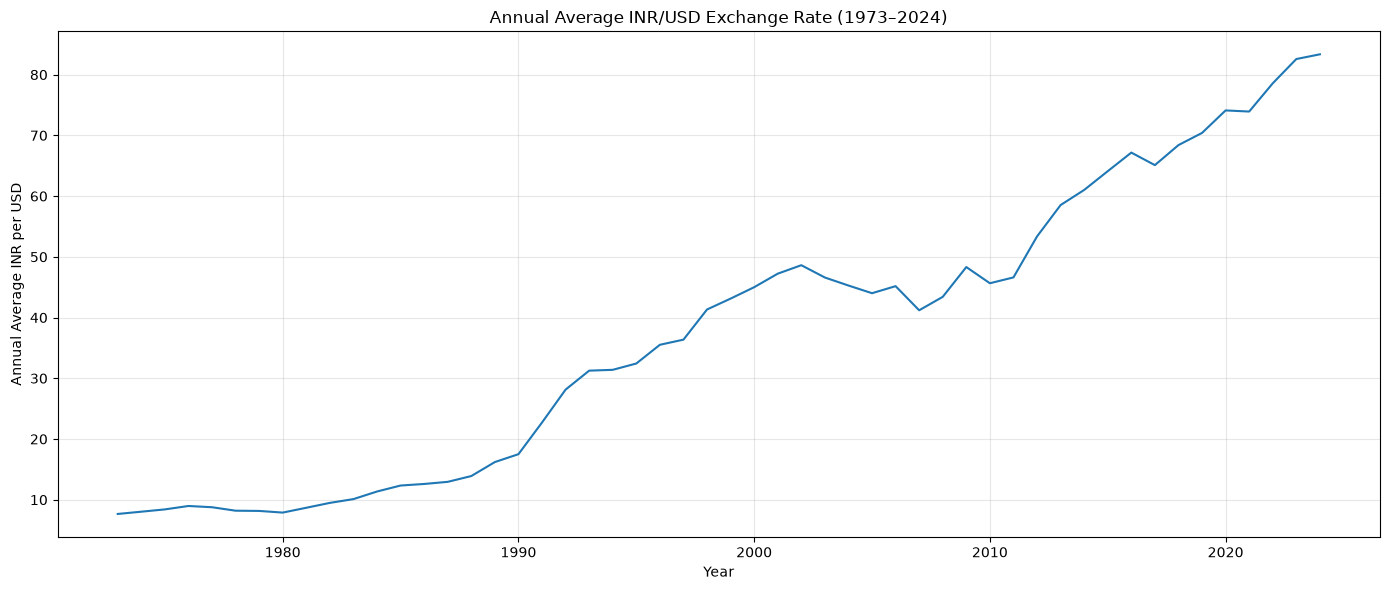

In [25]:
yearly_avg = (
    df.set_index("Date")["INR_per_USD"]
    .resample("YE")
    .mean()
)

plt.figure(figsize=(14, 6))

plt.plot(yearly_avg.index.year, yearly_avg.values)

plt.title("Annual Average INR/USD Exchange Rate (1973–2024)")
plt.xlabel("Year")
plt.ylabel("Annual Average INR per USD")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

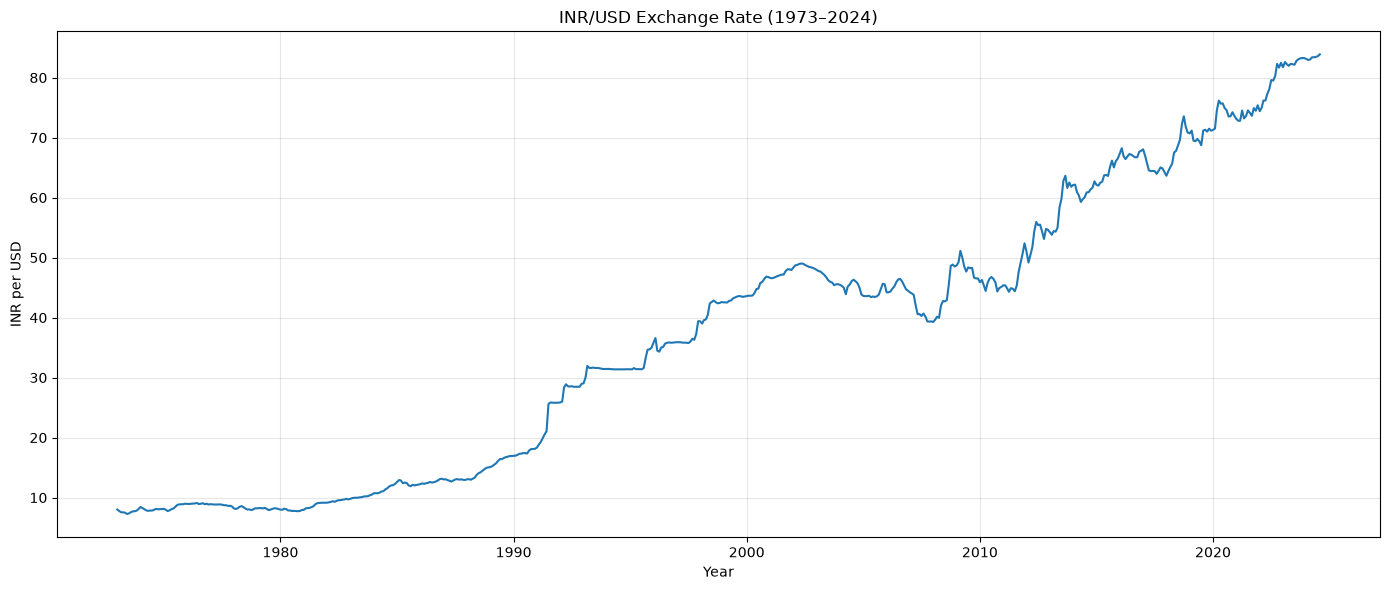

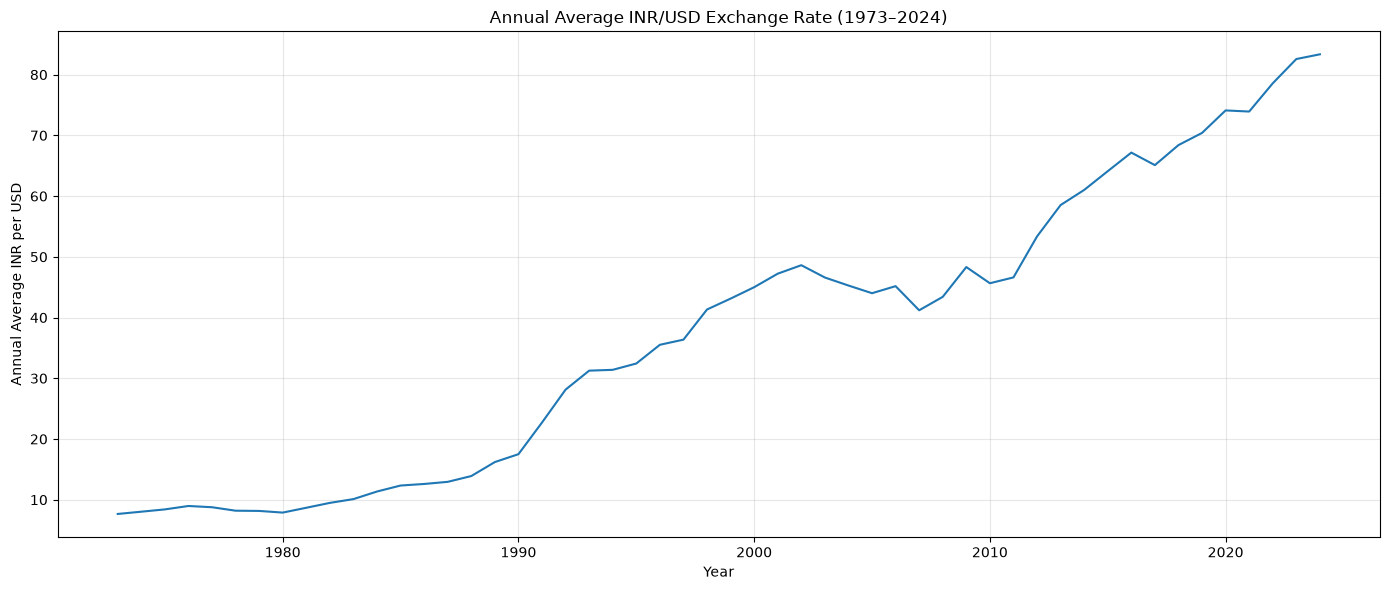

In [26]:
from pathlib import Path

output_dir = Path( r"C:\Users\Skyly\Documents\GitHub\INR_USD_Trend_Analysis\visualizations")
output_dir.mkdir(exist_ok=True)

plt.figure(figsize=(14, 6))
plt.plot(df["Date"], df["INR_per_USD"], linewidth=1.5)
plt.title("INR/USD Exchange Rate (1973–2024)")
plt.xlabel("Year")
plt.ylabel("INR per USD")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(output_dir / "monthly_exchange_rate.png", dpi=300)
plt.show()

plt.figure(figsize=(14, 6))
plt.plot(yearly_avg.index.year, yearly_avg.values)
plt.title("Annual Average INR/USD Exchange Rate (1973–2024)")
plt.xlabel("Year")
plt.ylabel("Annual Average INR per USD")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(output_dir / "annual_exchange_rate.png", dpi=300)
plt.show()

In [27]:
# Calculate annual percentage change
annual_analysis = yearly_avg.to_frame(name="INR_per_USD")

annual_analysis["Annual_Change_%"] = (
    annual_analysis["INR_per_USD"].pct_change() * 100
)

display(annual_analysis.round(2))


,INR_per_USD,Annual_Change_%
Date,,
1973-12-31,7.66,NaN
1974-12-31,8.03,4.88
1975-12-31,8.41,4.70
1976-12-31,8.97,6.68
1977-12-31,8.77,-2.27
1978-12-31,8.20,-6.52
1979-12-31,8.16,-0.47
1980-12-31,7.89,-3.33
1981-12-31,8.68,10.07


In [28]:
top_depreciation_years = (
    annual_analysis
    .dropna()
    .nlargest(5, "Annual_Change_%")
)

print("Top 5 years with highest INR depreciation:")
display(top_depreciation_years.round(2))

Top 5 years with highest INR depreciation:


,INR_per_USD,Annual_Change_%
Date,,
1991-12-31,22.72,29.81
1992-12-31,28.14,23.83
1989-12-31,16.21,16.57
2012-12-31,53.36,14.47
1998-12-31,41.33,13.65


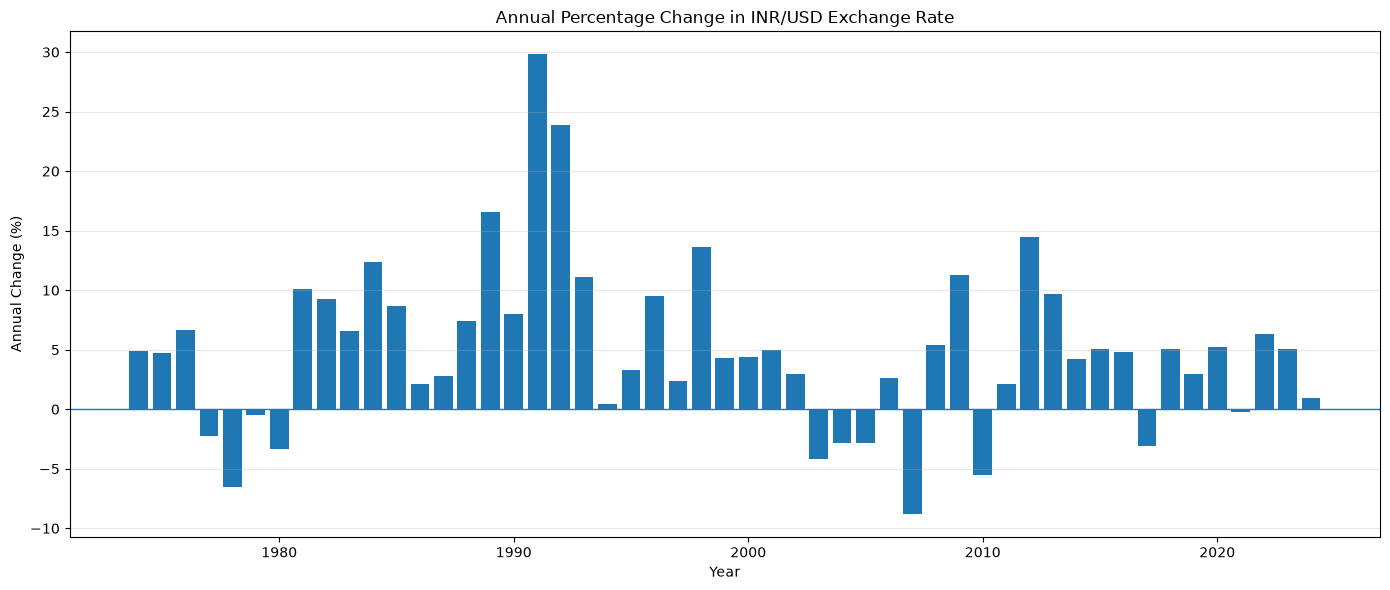

In [29]:
plt.figure(figsize=(14, 6))

plt.bar(
    annual_analysis.index.year,
    annual_analysis["Annual_Change_%"]
)

plt.axhline(0, linewidth=1)
plt.title("Annual Percentage Change in INR/USD Exchange Rate")
plt.xlabel("Year")
plt.ylabel("Annual Change (%)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [30]:
display(top_depreciation_years.round(2))

,INR_per_USD,Annual_Change_%
Date,,
1991-12-31,22.72,29.81
1992-12-31,28.14,23.83
1989-12-31,16.21,16.57
2012-12-31,53.36,14.47
1998-12-31,41.33,13.65


## Historical Analysis: Major INR Depreciation Periods

The annual exchange-rate analysis identifies 1991 and 1992 as the two years with the highest depreciation rates in the dataset.

- **1991 (29.81%):** India's balance-of-payments crisis and the two-step rupee adjustment in July 1991.
- **1992 (23.83%):** Continued exchange-rate adjustment and introduction of the Liberalised Exchange Rate Management System (LERMS).
- **1989 (16.57%):** A period of managed exchange-rate adjustments before the 1991 crisis.
- **2012 (14.47%):** A period of significant external-sector pressure requiring further investigation.
- **1998 (13.65%):** A period of economic and external-sector pressure requiring further investigation.

*Note: These percentages represent changes in annual average exchange rates calculated from the monthly dataset. They should not be interpreted as official one-time currency devaluation percentages.*

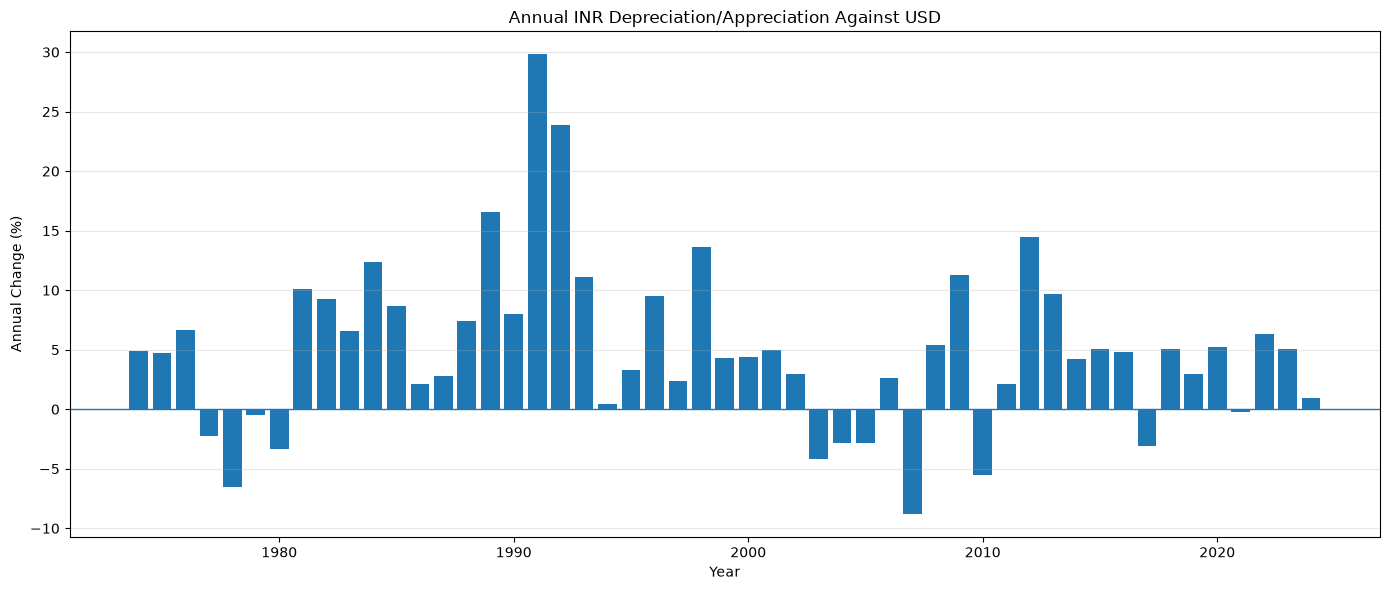

In [32]:
annual_analysis = yearly_avg.to_frame(name="INR_per_USD")

annual_analysis["Annual_Change_%"] = (
    annual_analysis["INR_per_USD"].pct_change() * 100
)

plt.figure(figsize=(14, 6))

plt.bar(
    annual_analysis.index.year,
    annual_analysis["Annual_Change_%"]
)

plt.axhline(0, linewidth=1)
plt.title("Annual INR Depreciation/Appreciation Against USD")
plt.xlabel("Year")
plt.ylabel("Annual Change (%)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    r"C:\Users\Skyly\Documents\GitHub\INR_USD_Trend_Analysis\visualizations\annual_inr_change.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()